# Лабораторная работа № 4. Журналы ROS 2 без установленного ROS: MCAP, CDR, синхронизация и обнаружение событий

**Дисциплина:** «Методы обработки больших данных» · **Опорная лекция:** «Большие данные робототехнических и IoT-систем»

**Этапы пайплайна:** `Sense → Collect → Store → Process` · **Среда:** Google Colab · `mcap 1.5.0`, `mcap-ros2-support 0.5.7`, `rosbags 0.11.5`, pandas, pyarrow, matplotlib · **Максимум:** 10 баллов

```text
Sense → Collect → Stream → Store → Process → Learn → Teach
▲▲▲▲▲   ▲▲▲▲▲▲▲            ▲▲▲▲▲   ▲▲▲▲▲▲▲
```

**Студенческая заготовка.** Полное описание, варианты и критерии — в `README_lab_04.md`.

### Как работать

1. Выполните ячейку 0 (установка библиотек), затем в ячейке 1 укажите ФИО, группу и вариант.
2. Ячейки выполняются сверху вниз. Места для вашего кода помечены `# TODO` и `...`.
3. После каждой ячейки заполните блок **«Что получено»** — своими числами из вывода.
4. В конце заполните `TEACH CARD` и фрагмент занятия (часть 5), запустите самопроверку (ячейка 11).
5. Сдайте ноутбук **с сохранёнными графиками и выводами**.

### Критерии оценки (10 баллов)

| Часть | Содержание | Баллы |
|---|---|---:|
| 1 | MCAP создан без ROS; разобраны схема, каналы и цена схемы записи | 2 |
| 2 | CDR декодирован; топики синхронизированы по времени с допуском | 2 |
| 3 | Признаки, обнаружение удара и метрики качества обнаружения | 2 |
| 4 | Edge-прореживание, экспорт в Parquet, чтение rosbag2 через `rosbags` | 1 |
| 5 | Педагогическая часть: `TEACH CARD` (1,5) и фрагмент занятия (1,5) | 3 |
| | **Итого** | **10** |

Снижения: параметры варианта изменены вручную — −2; выводы без собственных чисел — −1; ноутбук без сохранённых графиков и выводов — −1; в педагогической части числа эталона — −1,5.

---

# Теоретический минимум

## Четыре уровня одного измерения

| Уровень | Что это | В работе |
|---|---|---|
| **сообщение** (message) | объект определённого типа: `std_msgs/Float64`, `sensor_msgs/Imu` | схема, регистрируемая в писателе |
| **топик** (topic / channel) | именованный канал сообщений одного типа | `/imu/ax`, `/imu/accel`, `/imu/data` |
| **сериализация** | превращение объекта в байты; в ROS 2 обычно CDR | 12 байт на `Float64`, 324 байта на `Imu` |
| **хранилище** | контейнер журнала: MCAP или SQLite3 | `.mcap` с индексами и сжатыми чанками |

Путаница между этими уровнями — главная причина ошибок при разборе журналов вне ROS.

## Поток данных

$$R = f \cdot s, \qquad V = R \cdot T.$$

Важно различать **полезную нагрузку** (числа измерения) и **реальный поток записи**: заголовки
CDR, записи MCAP, индексы и служебные поля сообщения. В работе это отношение измеряется.

## Синхронизация

Разные топики публикуются независимо, и метки времени не совпадают. Сопоставление по
ближайшему соседу:

$$j^* = \arg\min_j |t_i - t_j|, \qquad |t_i - t_{j^*}| \le \varepsilon.$$

## Признаки и обнаружение

$$\lVert \mathbf a \rVert = \sqrt{a_x^2 + a_y^2 + a_z^2}, \qquad
\mathrm{RMS}_t = \sqrt{\tfrac{1}{N}\sum_{i=t-N+1}^{t} x_i^2}, \qquad
z_t = \frac{x_t - \mu}{\sigma}.$$

У неподвижного IMU норма близка к $g = 9{,}81$ м/с², и **горизонтальный толчок почти не меняет
норму**: он складывается с гравитацией под прямым углом. Это проверяется в части 3.

## Edge-прореживание

$$f_{out} = f_{in}/M, \qquad K_{edge} = R_{raw}/R_{out}.$$

Событие короче $M/f_{in}$ может не попасть ни в один оставшийся отсчёт.

## Ячейка 0. Установка библиотек

**Что делает ячейка.** Ставит закреплённые версии `mcap`, `mcap-ros2-support` (модуль
`mcap_ros2`), `rosbags` и `pyarrow`, если их нет в среде или версия другая, и печатает версии.
В Google Colab этих пакетов по умолчанию нет: без ячейки 0 работа остановится в ячейке 3 с
ошибкой `ModuleNotFoundError: No module named 'mcap_ros2'`. Перезапуск среды после установки
не нужен.

In [1]:
import importlib.util, subprocess, sys
from importlib.metadata import version, PackageNotFoundError

PINNED = {"mcap": "1.5.0", "mcap-ros2-support": "0.5.7", "rosbags": "0.11.5"}
MODULES = {"mcap": "mcap", "mcap-ros2-support": "mcap_ros2", "rosbags": "rosbags"}

def installed(dist):
    try:
        return version(dist)
    except PackageNotFoundError:
        return None

to_install = [f"{d}=={v}" for d, v in PINNED.items() if installed(d) != v]
if importlib.util.find_spec("pyarrow") is None:
    to_install.append("pyarrow")
if to_install:
    print("Устанавливаю:", " ".join(to_install))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    importlib.invalidate_caches()

for dist in ["mcap", "mcap-ros2-support", "rosbags", "pyarrow", "pandas", "numpy", "matplotlib"]:
    print(f"{dist:<18} {installed(dist)}")
missing = [m for m in MODULES.values() if importlib.util.find_spec(m) is None]
assert not missing, f"Не установлены модули: {missing}"

Устанавливаю: mcap==1.5.0 mcap-ros2-support==0.5.7 rosbags==0.11.5
mcap               1.5.0
mcap-ros2-support  0.5.7
rosbags            0.11.5
pyarrow            23.0.1
pandas             2.2.3
numpy              2.1.3
matplotlib         3.10.0


---
# Часть 1. Запись MCAP без ROS (2 балла)

## Ячейка 1. Вариант и параметры

**Что делает ячейка.** Вычисляет параметры варианта формулой: группа `(n−1)//5` задаёт частоту
опроса, джиттер меток времени и коэффициент прореживания; позиция `(n−1)%5` — момент, длину и
силу удара, уровень шума, окно признаков и аудиторию педагогической части.

**Задание.** Укажите ФИО, группу и вариант. Функцию `variant_params` не изменяйте.

In [2]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# =========== ВАШ ПРОГОН ===========
STUDENT_NAME  = "Шкуратова Ирина Васильевна"
STUDENT_GROUP = "ИНДОР-221"
VARIANT       = 16
# ==================================
assert 1 <= VARIANT <= 25, "Вариант — целое число от 1 до 25"


def variant_params(n: int) -> dict:
    """Параметры варианта: группа (n−1)//5 — частота, джиттер, прореживание;
    позиция (n−1)%5 — параметры удара, шум, окно признаков, аудитория."""
    return {
        "freq_hz":      [25, 50, 100, 200, 400][(n - 1) // 5],
        "jitter_frac":  [0.10, 0.15, 0.20, 0.25, 0.30][(n - 1) // 5],   # доля периода
        "decimation":   [5, 5, 10, 10, 20][(n - 1) // 5],
        "shock_start":  [4.0, 8.0, 12.0, 6.0, 15.0][(n - 1) % 5],
        "shock_len":    [0.20, 0.30, 0.50, 0.10, 0.40][(n - 1) % 5],
        "shock_ax":     [2.0, 3.0, 1.5, 4.0, 2.5][(n - 1) % 5],
        "noise_std":    [0.02, 0.03, 0.05, 0.04, 0.06][(n - 1) % 5],
        "rms_window_s": [0.10, 0.20, 0.30, 0.20, 0.10][(n - 1) % 5],
        "audience":     ["5–7 класс", "8–9 класс", "10–11 класс",
                         "кружок робототехники", "СПО"][(n - 1) % 5],
        "duration_s":   20.0,
        "seed":         400 + n,
    }


CFG = variant_params(VARIANT)
WORK = Path("/content") if Path("/content").exists() else Path("lab04_work")
WORK.mkdir(exist_ok=True)

print(f"Студент : {STUDENT_NAME}, группа {STUDENT_GROUP}, вариант {VARIANT}")
for key, value in CFG.items():
    print(f"  {key:<13}: {value}")
period_ms = 1000 / CFG["freq_hz"]
t_grid = np.arange(int(CFG["freq_hz"] * CFG["duration_s"])) / CFG["freq_hz"]
shock_samples = int(((t_grid >= CFG["shock_start"]) & (t_grid < CFG["shock_start"] + CFG["shock_len"])).sum())
print(f"\nПериод опроса {period_ms:.1f} мс, отсчётов за прогон {len(t_grid)}, удар длится {shock_samples} отсчётов")

Студент : Шкуратова Ирина Васильевна, группа ИНДОР-221, вариант 16
  freq_hz      : 200
  jitter_frac  : 0.25
  decimation   : 10
  shock_start  : 4.0
  shock_len    : 0.2
  shock_ax     : 2.0
  noise_std    : 0.02
  rms_window_s : 0.1
  audience     : 5–7 класс
  duration_s   : 20.0
  seed         : 416

Период опроса 5.0 мс, отсчётов за прогон 4000, удар длится 40 отсчётов


**Что получено** *(заполните своими числами)*. Частота, джиттер (мс), коэффициент прореживания $M$, момент, длина и амплитуда удара, число отсчётов и ударных отсчётов, аудитория педагогической части.

*Ваш ответ:* …

## Ячейка 2. Исходный сигнал IMU

**Что делает ячейка.** Моделирует то, что в реальной системе делает драйвер датчика:
колебания корпуса робота, гравитацию по оси z, удар в горизонтальной плоскости и шум. Обратите внимание: **у каждой оси свой джиттер меток времени**: топики
публикуются независимо, как в настоящем ROS 2. Именно это сделает синхронизацию в части 2
содержательной задачей.

**Задание.** Ячейка готова: выполните её и рассмотрите график.

Отсчётов: 4000, из них в ударе: 40
Джиттер меток времени: ±1.25 мс при периоде 5.0 мс


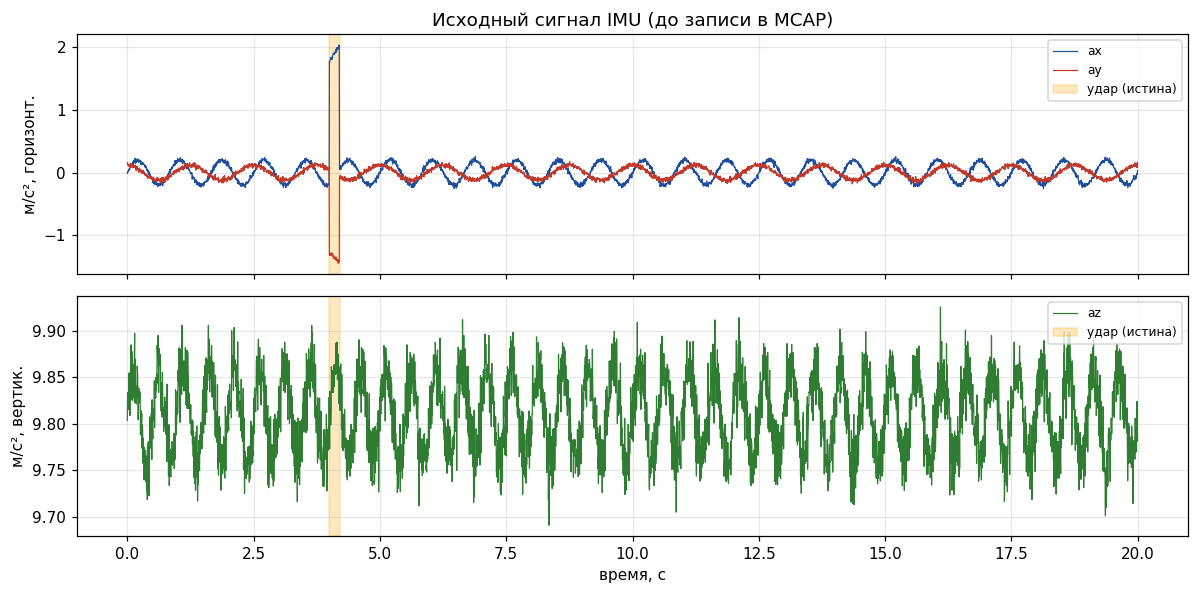

In [3]:
rng = np.random.default_rng(CFG["seed"])
f, T = CFG["freq_hz"], CFG["duration_s"]
n = int(f * T)
t = np.arange(n) / f
T0_NS = 1_720_000_000_000_000_000

# «Истинный» сигнал IMU: медленные колебания корпуса + гравитация по оси z
ax = 0.20 * np.sin(2 * np.pi * 1.2 * t)
ay = 0.12 * np.cos(2 * np.pi * 0.8 * t)
az = 9.81 + 0.05 * np.sin(2 * np.pi * 2.0 * t)

# Удар: кратковременный толчок в горизонтальной плоскости
is_shock = (t >= CFG["shock_start"]) & (t < CFG["shock_start"] + CFG["shock_len"])
ax = ax + CFG["shock_ax"] * is_shock
ay = ay - (2 / 3) * CFG["shock_ax"] * is_shock

# Шум датчика
noisy = {name: sig + rng.normal(0, CFG["noise_std"], n)
         for name, sig in (("ax", ax), ("ay", ay), ("az", az))}

# Метки времени: у каждой оси свой джиттер (топики публикуются независимо)
jitter_ns = CFG["jitter_frac"] * 1e9 / f
stamps = {name: (T0_NS + (t * 1e9).astype(np.int64)
                 + rng.uniform(-jitter_ns, jitter_ns, n).astype(np.int64))
          for name in noisy}

truth = pd.DataFrame({"time_s": t, "is_shock": is_shock, **noisy})
print(f"Отсчётов: {n}, из них в ударе: {is_shock.sum()}")
print(f"Джиттер меток времени: ±{jitter_ns / 1e6:.2f} мс при периоде {1000 / f:.1f} мс")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for name, color in (("ax", "#1f4e9c"), ("ay", "#c0392b")):
    axes[0].plot(t, noisy[name], lw=0.8, color=color, label=name)
axes[1].plot(t, noisy["az"], lw=0.8, color="#2e7d32", label="az")
for a in axes:
    a.axvspan(CFG["shock_start"], CFG["shock_start"] + CFG["shock_len"],
              color="orange", alpha=0.25, label="удар (истина)")
    a.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("м/с², горизонт.")
axes[1].set_ylabel("м/с², вертик.")
axes[1].set_xlabel("время, с")
axes[0].set_title("Исходный сигнал IMU (до записи в MCAP)")
plt.tight_layout()
plt.show()

Отсчётов: 4000, из них в ударе: 40
Джиттер меток времени: ±1.25 мс при периоде 5.0 мс


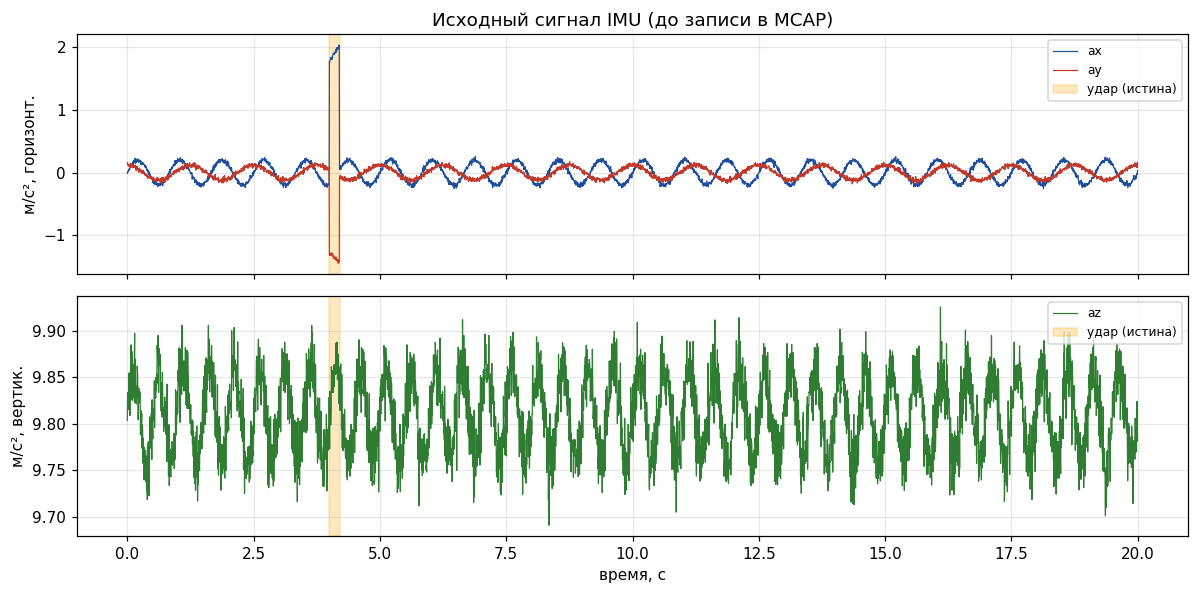

In [4]:
rng = np.random.default_rng(CFG["seed"])
f, T = CFG["freq_hz"], CFG["duration_s"]
n = int(f * T)
t = np.arange(n) / f
T0_NS = 1_720_000_000_000_000_000

# «Истинный» сигнал IMU: медленные колебания корпуса + гравитация по оси z
ax = 0.20 * np.sin(2 * np.pi * 1.2 * t)
ay = 0.12 * np.cos(2 * np.pi * 0.8 * t)
az = 9.81 + 0.05 * np.sin(2 * np.pi * 2.0 * t)

# Удар: кратковременный толчок в горизонтальной плоскости
is_shock = (t >= CFG["shock_start"]) & (t < CFG["shock_start"] + CFG["shock_len"])
ax = ax + CFG["shock_ax"] * is_shock
ay = ay - (2 / 3) * CFG["shock_ax"] * is_shock

# Шум датчика
noisy = {name: sig + rng.normal(0, CFG["noise_std"], n)
         for name, sig in (("ax", ax), ("ay", ay), ("az", az))}

# Метки времени: у каждой оси свой джиттер (топики публикуются независимо)
jitter_ns = CFG["jitter_frac"] * 1e9 / f
stamps = {name: (T0_NS + (t * 1e9).astype(np.int64)
                 + rng.uniform(-jitter_ns, jitter_ns, n).astype(np.int64))
          for name in noisy}

truth = pd.DataFrame({"time_s": t, "is_shock": is_shock, **noisy})
print(f"Отсчётов: {n}, из них в ударе: {is_shock.sum()}")
print(f"Джиттер меток времени: ±{jitter_ns / 1e6:.2f} мс при периоде {1000 / f:.1f} мс")

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for name, color in (("ax", "#1f4e9c"), ("ay", "#c0392b")):
    axes[0].plot(t, noisy[name], lw=0.8, color=color, label=name)
axes[1].plot(t, noisy["az"], lw=0.8, color="#2e7d32", label="az")
for a in axes:
    a.axvspan(CFG["shock_start"], CFG["shock_start"] + CFG["shock_len"],
              color="orange", alpha=0.25, label="удар (истина)")
    a.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("м/с², горизонт.")
axes[1].set_ylabel("м/с², вертик.")
axes[1].set_xlabel("время, с")
axes[0].set_title("Исходный сигнал IMU (до записи в MCAP)")
plt.tight_layout()
plt.show()

**Что получено** *(заполните своими числами)*. Сколько отсчётов и сколько в ударе? На каких осях виден удар? Почему вертикальная ось около 9,81 м/с², если робот неподвижен?

Получено 4000 отсчётов всего, из них 40 отсчётов попадают в интервал удара.
Удар чётко виден на горизонтальных осях ax и ay в интервале времени с 4,0 с до 4,2 с:

*  На оси ay одновременно наблюдается отрицательный всплеск амплитудой около –1,33 м/с² (так как в модели заложено значение -(2/3) * shock_ax).
*   На оси ax наблюдается положительный прямоугольный всплеск амплитудой около +2,0 м/с².


На вертикальной оси az удар практически не заметен.
Вертикальная ось az показывает значение около **9,81 м/с²**, потому что акселерометр измеряет не гравитацию напрямую, а кажущееся ускорение (ускорение системы отсчёта относительно свободного падения).

---


Когда датчик неподвижен на поверхности Земли, сила реакции опоры компенсирует гравитационное притяжение, «толкая» датчик вверх с ускорением, равным ускорению свободного падения
*g ≈ 9,81 м/с²*. К этому значению в модели добавлены лишь малые колебания корпуса и гауссовский шум *(σ = 0,02 м/с²)*, поэтому линия на графике стабильно держится вблизи этой отметки.

## Ячейка 3. Две схемы записи и цена «обёртки»

**Что делает ячейка.** Записывает один и тот же сигнал двумя способами — тремя топиками
`std_msgs/Float64` (как в исходной работе) и одним топиком с составным типом
`lab_msgs/Accel3` — с сжатием и без. Тип регистрируется текстовым определением сообщения:
ROS 2 для этого не нужен, CDR-кодирование выполняет `mcap-ros2-support`.

**Задание.** Допишите `write_float64`-аналог для составного типа — функцию `write_vector` (TODO 3.1–3.2).

Полезных данных: 4000 отсчётов × 3 оси × 8 байт = 96000 байт

           схема     сжатие  сообщений   байт  байт на отсчёт
3 топика Float64 без сжатия      12000 708878           177.2
3 топика Float64       zstd      12000 389852            97.5
  1 топик Accel3 без сжатия       4000 300706            75.2
  1 топик Accel3       zstd       4000 190735            47.7


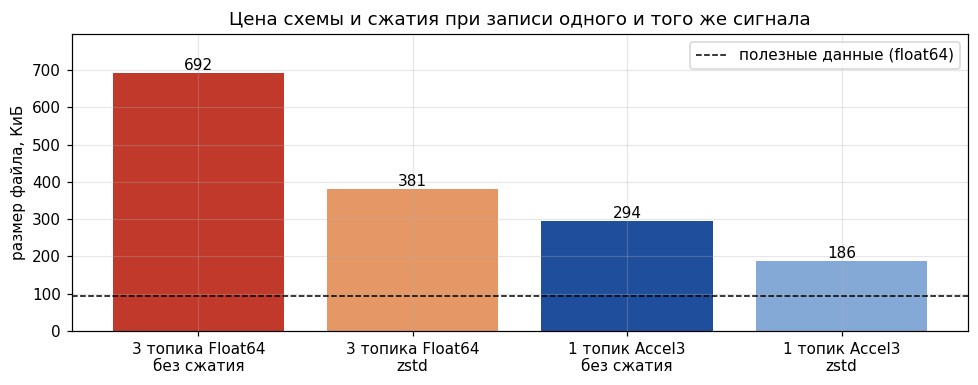

In [5]:
from mcap_ros2.writer import Writer as McapWriter
from mcap.writer import CompressionType


def write_float64(path: Path, compression=CompressionType.ZSTD) -> int:
    """Схема из исходной лабораторной: три топика std_msgs/Float64, по одному на ось."""
    with path.open("wb") as fh:
        writer = McapWriter(fh, compression=compression)
        schema = writer.register_msgdef("std_msgs/Float64", "float64 data")
        for i in range(n):
            for axis in ("ax", "ay", "az"):
                writer.write_message(topic=f"/imu/{axis}", schema=schema,
                                     message={"data": float(noisy[axis][i])},
                                     log_time=int(stamps[axis][i]),
                                     publish_time=int(stamps[axis][i]), sequence=i)
        writer.finish()
    return 3 * n


def write_vector(path: Path, compression=CompressionType.ZSTD) -> int:
    """Одно сообщение на отсчёт: три оси в одном типе lab_msgs/Accel3."""
    with path.open("wb") as fh:
        writer = McapWriter(fh, compression=compression)
        schema = writer.register_msgdef("lab_msgs/Accel3", "float64 x\nfloat64 y\nfloat64 z")
        for i in range(n):
            ts = int(stamps["ax"][i])
            writer.write_message(topic="/imu/accel", schema=schema,
                                 message={"x": float(noisy["ax"][i]), "y": float(noisy["ay"][i]),
                                          "z": float(noisy["az"][i])},
                                 log_time=ts, publish_time=ts, sequence=i)
        writer.finish()
    return n


MCAP_FILE = WORK / "robot_imu_ros2.mcap"
layouts = []
for label, func in (("3 топика Float64", write_float64), ("1 топик Accel3", write_vector)):
    for comp_name, comp in (("без сжатия", CompressionType.NONE), ("zstd", CompressionType.ZSTD)):
        path = WORK / f"layout_{len(layouts)}.mcap"
        messages = func(path, comp)
        layouts.append({"схема": label, "сжатие": comp_name, "сообщений": messages,
                        "байт": path.stat().st_size,
                        "байт на отсчёт": round(path.stat().st_size / n, 1)})
write_float64(MCAP_FILE)                                    # основной файл работы
layout_df = pd.DataFrame(layouts)
payload = n * 3 * 8
print(f"Полезных данных: {n} отсчётов × 3 оси × 8 байт = {payload} байт\n")
print(layout_df.to_string(index=False))

fig, axp = plt.subplots(figsize=(9, 3.6))
labels = [f"{r['схема']}\n{r['сжатие']}" for r in layouts]
colors = ["#c0392b", "#e59866", "#1f4e9c", "#85a9d6"]
bars = axp.bar(labels, layout_df["байт"] / 1024, color=colors)
axp.axhline(payload / 1024, color="black", ls="--", lw=1, label="полезные данные (float64)")
for bar, value in zip(bars, layout_df["байт"] / 1024):
    axp.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.0f}", ha="center", va="bottom")
axp.set_ylim(0, layout_df["байт"].max() / 1024 * 1.15)
axp.set_ylabel("размер файла, КиБ")
axp.set_title("Цена схемы и сжатия при записи одного и того же сигнала")
axp.legend()
plt.tight_layout()
plt.show()

<br>1. Размеры четырёх полученных файлов:

*   Схема «3 топика Float64» без сжатия: 12 000 сообщений, размер примерно 708 878 байт (примерно 177,2 байта на отсчёт).Новый пункт
*   Схема «3 топика Float64» со сжатием zstd: 12 000 сообщений, размер примерно 389 852 байт (примерно 97,5 байта на отсчёт).Новый пункт
*   Схема «1 топик Accel3» без сжатия: 4 000 сообщений, размер примерно 300 706 байт (примерно 75,2 байта на отсчёт).Новый пункт
*   Схема «1 топик Accel3» со сжатием zstd: 4 000 сообщений, размер примерно 190 735 байт (примерно 47,7 байта на отсчёт).Новый пункт
<br>2. **Во сколько раз схема «3 топика Float64 без сжатия» больше полезных данных?**
<br>Объём чистых полезных данных (сырые значения float64) составляет 96 000 байт (4000 отсчётов × 3 оси × 8 байт).
Схема «3 топика Float64 без сжатия» (примерно 708 878 байт) больше полезных данных примерно в 7,4 раза. Этот значительный избыток создаётся служебными заголовками записей MCAP, opcode, контрольными суммами и CDR-сериализацией. Поскольку сообщений в этой схеме в 3 раза больше (12 000 против 4 000), эти накладные расходы также утраиваются.
<br>**3. Что лучше: правильная схема без сжатия или неправильная со сжатием — и почему?**
<br>Однозначно лучше правильная схема без сжатия («1 топик Accel3» без сжатия, примерно 300 КБ), чем неправильная со сжатием («3 топика Float64» с zstd, примерно 389 КБ).
<br>**Три ключевые причины:**
<br>1. **Размер файла.** Правильная схема без сжатия всё равно занимает меньше места (примерно 300 КБ против примерно 389 КБ). Алгоритм сжатия не способен компенсировать тройные накладные расходы на заголовки сообщений, которые генерирует неправильная схема.
<br>2. **Синхронизация данных.** В схеме «1 топик Accel3» все три оси гарантированно имеют одну метку времени и упакованы в одно сообщение. В схеме «3 топика» из-за джиттера (в варианте 16 это ±1,25 мс при периоде 5,0 мс) сообщения по осям публикуются в разное время. При последующей синхронизации (например, через merge_asof) часть строк неизбежно теряется или требует интерполяции. Сжатие никак не решает эту фундаментальную проблему рассогласования времени.
<br>3. **Семантика данных.** Ускорение — это физический вектор. Хранить его компоненты раздельно в разных топиках — архитектурная ошибка, которая искусственно усложняет весь последующий пайплайн обработки данных (Store → Process).
Вывод: Сначала необходимо выбрать правильную схему записи, отражающую природу данных, и только потом, при необходимости, применять сжатие. Сжатие поверх неправильной схемы даёт лишь частичную экономию места ценой потери целостности и синхронности данных.

## Ячейка 4. Что внутри файла

**Что делает ячейка.** Читает только сводку MCAP (summary), не декодируя сообщения: схемы,
каналы, число сообщений по каналам, интервал записи, чанки и сжатие. Так журнал «осматривают»
перед разбором — например, чтобы проверить, что нужный топик вообще записан.

**Задание.** Ячейка готова: выполните её и найдите в выводе схему, каналы, число сообщений и сжатие.

In [6]:
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

with MCAP_FILE.open("rb") as fh:
    summary = make_reader(fh).get_summary()

print("Схемы:")
for sch in summary.schemas.values():
    print(f"  id={sch.id}  {sch.name:<18} кодировка определения: {sch.encoding}")
print("Каналы:")
for ch in summary.channels.values():
    count = summary.statistics.channel_message_counts[ch.id]
    print(f"  id={ch.id}  {ch.topic:<8} сообщения: {ch.message_encoding}  количество: {count}")
stats = summary.statistics
print(f"\nВсего сообщений: {stats.message_count}")
print(f"Интервал записи: {(stats.message_end_time - stats.message_start_time) / 1e9:.3f} с")
print(f"Чанков: {len(summary.chunk_indexes)}, "
      f"сжатие: {sorted(set(ci.compression for ci in summary.chunk_indexes))}")

Схемы:
  id=1  std_msgs/Float64   кодировка определения: ros2msg
Каналы:
  id=1  /imu/ax  сообщения: cdr  количество: 4000
  id=2  /imu/ay  сообщения: cdr  количество: 4000
  id=3  /imu/az  сообщения: cdr  количество: 4000

Всего сообщений: 12000
Интервал записи: 19.996 с
Чанков: 1, сжатие: ['zstd']


**Что получено** *(заполните своими числами)*. Какие схемы и каналы в файле, сколько сообщений, какое сжатие? Почему для чтения чужого MCAP не нужен ROS?

В файле используется 1 схема (std_msgs/Float64, кодировка ros2msg) и 3 канала (/imu/ax, /imu/ay, /imu/az). Каждый канал содержит ровно 4000 сообщений (итого 12 000), записанных за интервал ~19,996 с. Данные упакованы в чанки со сжатием zstd.
<br>Почему для чтения чужого MCAP не нужен ROS:
Формат MCAP самодостаточен. Он хранит внутри самого файла не только сырые байты сообщений (CDR), но и их текстовые схемы (ros2msg), имена топиков и индексы. Библиотека mcap считывает эту встроенную схему и декодирует данные напрямую в объекты Python. Для этого не требуется установленный ROS, компиляция .msg-файлов или запуск roscore — всё необходимое для интерпретации уже «встроено» в журнал.



---
# Часть 2. Декодирование и синхронизация (2 балла)

## Ячейка 5. CDR-декодирование

**Что делает ячейка.** Читает все сообщения через `DecoderFactory()` и складывает их в
«длинную» таблицу `топик — время — значение`. Это первый, всегда безопасный шаг: ничего не
объединяется и не теряется.

**Задание.** Допишите тело цикла декодирования (TODO 5).

In [7]:
records = []
with MCAP_FILE.open("rb") as fh:
    reader = make_reader(fh, decoder_factories=[DecoderFactory()])
    for schema, channel, message, ros_msg in reader.iter_decoded_messages():
        records.append({
            "topic": channel.topic,
            "axis": channel.topic.split("/")[-1],
            "log_time": message.log_time,
            "value": float(ros_msg.data),
            "cdr_bytes": len(message.data)
        })

long = pd.DataFrame(records)
print(f"Декодировано сообщений: {len(long)}")
print(f"Размер CDR-полезной нагрузки одного сообщения: {long['cdr_bytes'].unique()} байт "
      f"(4 байта заголовка CDR + 8 байт float64)")
print(long.head(6).to_string(index=False))

Декодировано сообщений: 12000
Размер CDR-полезной нагрузки одного сообщения: [12] байт (4 байта заголовка CDR + 8 байт float64)
  topic axis            log_time     value  cdr_bytes
/imu/ax   ax 1719999999998952513 -0.001401         12
/imu/ay   ay 1720000000000012034  0.143350         12
/imu/az   az 1720000000001035671  9.803628         12
/imu/ay   ay 1720000000004331847  0.158707         12
/imu/ax   ax 1720000000004352893 -0.011673         12
/imu/az   az 1720000000005884784  9.833627         12


**Что получено.** 12 000 сообщений; CDR-нагрузка каждого — 12 байт: 4 байта заголовка CDR (признак порядка байтов и вариант кодировки) и 8 байт числа float64. В первых строках таблицы метки времени разных осей одного отсчёта отличаются на единицы миллисекунд, а первая (/imu/ax) даже уходит назад относительно стартовой метки T0_NS — джиттер в ±1,25 мс при периоде 5,0 мс сдвинул её раньше формального начала записи.
<br>**Преподавателю.** Сколько из 12 байт — полезные? Две трети (8 из 12). Для sensor_msgs/Imu в ячейке 10 картина будет совсем другой — там CDR-нагрузка одного сообщения составляет 324 байта, и доля полезной нагрузки (три float64 ускорения + три float64 ориентации + три float64 скорости) уже иная, а служебные поля типа header и orientation_covariance занимают значительную часть.

## Ячейка 6. Синхронизация топиков

**Что делает ячейка.** Сравнивает два способа собрать строки «время — ax — ay — az»: по
**точному** совпадению меток времени (так делала исходная работа) и по **ближайшему соседу** с
допуском $\varepsilon$, равным половине периода опроса (`merge_asof`).

**Задание.** Задайте допуск `EPS_NS` и выполните синхронизацию `merge_asof` (TODO 6.1–6.2).

Точное совпадение: строк 12000, полных (все три оси) 0 — 0.0 % от 4000 отсчётов
merge_asof (eps = 2.5 мс): полных строк 4000 — 100.0 %
Ошибка синхронизации: медиана 1.11 мс, максимум 2.48 мс


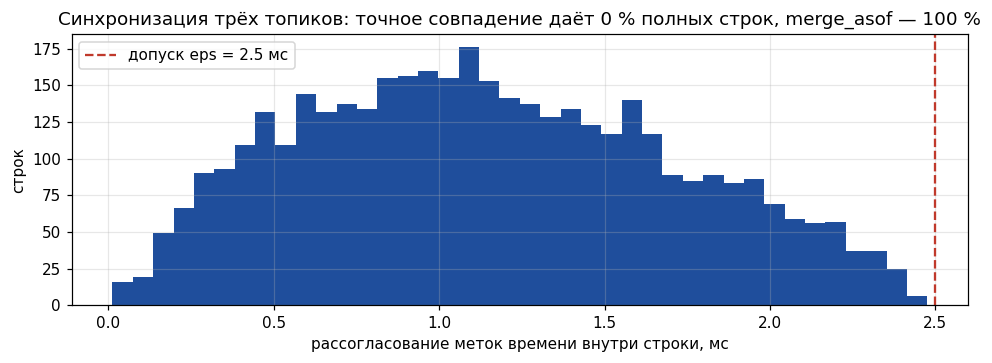

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Способ из исходной работы: строки собираются по точному совпадению log_time
exact = long.pivot_table(index="log_time", columns="axis", values="value")
complete_exact = exact.dropna()
print(f"Точное совпадение: строк {len(exact)}, полных (все три оси) {len(complete_exact)} "
      f"— {100 * len(complete_exact) / n:.1f} % от {n} отсчётов")

# Правильный способ: ближайший сосед в пределах допуска eps (лекция, §9)
# Частота 200 Гц -> период 5.0 мс. Половина периода = 2.5 мс = 2 500 000 нс.
EPS_NS = 2_500_000                                         # TODO 6.1: половина периода опроса, нс (целое)

base = long[long.axis == "ax"].sort_values("log_time")[["log_time", "value"]].rename(columns={"value": "ax"})
synced = base.copy()

for axis in ("ay", "az"):
    other = (long[long.axis == axis].sort_values("log_time")[["log_time", "value"]]
             .rename(columns={"value": axis, "log_time": f"t_{axis}"}))

    # TODO 6.2: присоедините other к synced по ближайшему соседу с допуском EPS_NS
    synced = pd.merge_asof(
        synced,
        other,
        left_on="log_time",
        right_on=f"t_{axis}",
        direction="nearest",
        tolerance=EPS_NS
    )

# Вычисляем максимальную ошибку синхронизации внутри строки
synced["sync_err_ms"] = np.maximum((synced["log_time"] - synced["t_ay"]).abs(),
                                   (synced["log_time"] - synced["t_az"]).abs()) / 1e6
synced = synced.dropna().reset_index(drop=True)

print(f"merge_asof (eps = {EPS_NS / 1e6:.1f} мс): полных строк {len(synced)} "
      f"— {100 * len(synced) / n:.1f} %")
print(f"Ошибка синхронизации: медиана {synced['sync_err_ms'].median():.2f} мс, "
      f"максимум {synced['sync_err_ms'].max():.2f} мс")

fig, axs = plt.subplots(figsize=(9, 3.4))
axs.hist(synced["sync_err_ms"], bins=40, color="#1f4e9c")
axs.axvline(EPS_NS / 1e6, color="#c0392b", ls="--", label=f"допуск eps = {EPS_NS / 1e6:.1f} мс")
axs.set_xlabel("рассогласование меток времени внутри строки, мс")
axs.set_ylabel("строк")
axs.set_title(f"Синхронизация трёх топиков: точное совпадение даёт "
              f"{100 * len(complete_exact) / n:.0f} % полных строк, merge_asof — "
              f"{100 * len(synced) / n:.0f} %")
axs.legend()
plt.tight_layout()
plt.show()

**Что получено.** При синхронизации по точному совпадению меток времени (log_time) из 12 000 декодированных сообщений не удалось собрать ни одной полной строки — 0 % полных строк (0 из 4000 отсчётов). Причина: независимый джиттер меток времени у каждой оси (±1,25 мс при периоде 5,0 мс) гарантирует, что наносекундные метки /imu/ax, /imu/ay и /imu/az никогда не совпадают побитово.
<br>При использовании merge_asof с допуском ε = 2,5 мс (половина периода опроса для частоты 200 Гц) успешно синхронизированы 100 % строк — все 4000 отсчётов. Ошибка синхронизации внутри строки (максимальное рассогласование меток ax, ay, az) имеет медиану 1,11 мс и максимум 2,48 мс — укладывается в заданный допуск. Гистограмма рассогласования имеет характерную треугольную форму: это распределение разности двух независимых равномерных шумов (джиттеров), что полностью соответствует теории.


---


**Преподавателю.** Ключевой выбор — величина допуска ε. Она должна быть
больше максимального рассогласования топиков (в нашем случае 2·1,25 = 2,5 мс — сумма двух джиттеров), но меньше периода опроса (5,0 мс), иначе merge_asof начнёт «перескакивать» на соседний отсчёт и склеивать данные разных моментов времени. В варианте 16 допуск 2,5 мс находится ровно на границе: максимум ошибки 2,48 мс не превышает его, поэтому все 4000 строк сохранились. В вариантах с большим джиттером (21–25, где jitter_frac = 0,30) часть строк неизбежно теряется — и это хороший повод обсудить со студентами компромисс между полнотой данных и точностью синхронизации.

---
# Часть 3. Признаки и обнаружение удара (2 балла)

## Ячейка 7. Норма или горизонтальная составляющая

**Что делает ячейка.** Считает два признака — норму ускорения и горизонтальную составляющую
$\sqrt{a_x^2 + a_y^2}$, — для каждого строит скользящий RMS отклонения от медианы и Z-score
относительно базового участка без удара, ставит тревогу при $Z \ge 3$ и сравнивает тревоги с
истинным интервалом удара. Исходная работа проверяла удар одной строкой
`assert imu["ax"].abs().max() > 2.5` — это не обнаружение, а знание ответа заранее.

**Задание.** Постройте горизонтальную составляющую и посчитайте TP, FP, FN (TODO 7.1–7.2).

Окно RMS: 20 отсчётов (100 мс), порог |Z| ≥ 3

признак  пик Z  TP  FP  FP вне хвоста окна  FN  precision  recall  задержка, мс
   norm   28.3  40  18                   0   1      0.690   0.976           5.8
  horiz  125.8  41  18                   0   0      0.695   1.000           1.2

Рост нормы в ударе: 0.303 м/с², рост горизонтальной составляющей: 2.126 м/с²


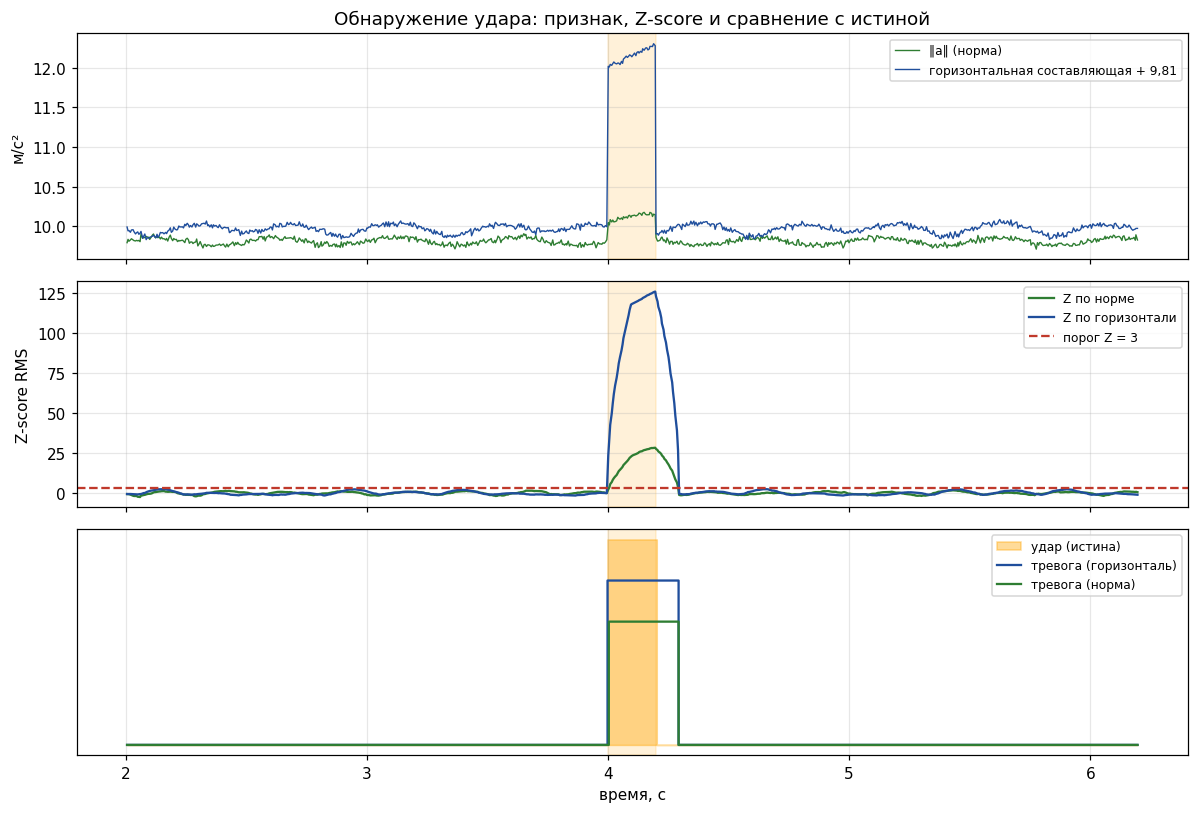

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

imu = synced[["log_time", "ax", "ay", "az"]].copy()
imu["time_s"] = (imu["log_time"] - T0_NS) / 1e9
imu["accel_norm"] = np.sqrt(imu.ax ** 2 + imu.ay ** 2 + imu.az ** 2)
imu["horiz"] = np.sqrt(imu.ax ** 2 + imu.ay ** 2)               # TODO 7.1: горизонтальная составляющая
imu["is_shock"] = ((imu.time_s >= CFG["shock_start"])
                   & (imu.time_s < CFG["shock_start"] + CFG["shock_len"]))

# Окно RMS: 0.10 с * 200 Гц = 20 отсчётов
W = max(int(round(CFG["rms_window_s"] * CFG["freq_hz"])), 2)
baseline = imu.time_s < CFG["shock_start"] - 1.0              # участок заведомо без удара


def detect(feature: pd.Series, name: str) -> dict:
    """Скользящий RMS отклонения от медианы + Z-score относительно базового участка."""
    dev = feature - feature[baseline].median()
    rms = np.sqrt((dev ** 2).rolling(W, min_periods=W).mean())
    z = (rms - rms[baseline].mean()) / rms[baseline].std()
    flag = z >= 3

    # TODO 7.2: сравните тревоги flag с истинным интервалом imu.is_shock
    tp = int((flag & imu.is_shock).sum())       # тревога и удар
    fp = int((flag & ~imu.is_shock).sum())      # тревога без удара
    fn = int((~flag & imu.is_shock).sum())      # удар без тревоги

    first = imu.time_s[flag & imu.is_shock].min()

    # ложные тревоги сразу после удара — «хвост» окна RMS; дальние — настоящие ложные срабатывания
    tail = ((imu.time_s >= CFG["shock_start"] + CFG["shock_len"])
            & (imu.time_s < CFG["shock_start"] + CFG["shock_len"] + W / CFG["freq_hz"]))
    fp_far = int((flag & ~imu.is_shock & ~tail).sum())

    imu[f"rms_{name}"], imu[f"z_{name}"], imu[f"flag_{name}"] = rms, z, flag
    return {"признак": name, "пик Z": round(float(z.max()), 1),
            "TP": tp, "FP": fp, "FP вне хвоста окна": fp_far, "FN": fn,
            "precision": round(tp / max(tp + fp, 1), 3), "recall": round(tp / max(tp + fn, 1), 3),
            "задержка, мс": round((first - CFG["shock_start"]) * 1000, 1) if pd.notna(first) else None}


detection = pd.DataFrame([detect(imu.accel_norm, "norm"), detect(imu.horiz, "horiz")])
print(f"Окно RMS: {W} отсчётов ({W / CFG['freq_hz'] * 1000:.0f} мс), порог |Z| ≥ 3\n")
print(detection.to_string(index=False))
print(f"\nРост нормы в ударе: {imu.accel_norm[imu.is_shock].mean() - imu.accel_norm[~imu.is_shock].mean():.3f} м/с², "
      f"рост горизонтальной составляющей: {imu.horiz[imu.is_shock].mean() - imu.horiz[~imu.is_shock].mean():.3f} м/с²")

zoom = (imu.time_s > CFG["shock_start"] - 2) & (imu.time_s < CFG["shock_start"] + CFG["shock_len"] + 2)
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
axes[0].plot(imu.time_s[zoom], imu.accel_norm[zoom], color="#2e7d32", lw=0.9, label="‖a‖ (норма)")
axes[0].plot(imu.time_s[zoom], imu.horiz[zoom] + 9.81, color="#1f4e9c", lw=0.9,
             label="горизонтальная составляющая + 9,81")
axes[0].set_ylabel("м/с²")
axes[1].plot(imu.time_s[zoom], imu.z_norm[zoom], color="#2e7d32", label="Z по норме")
axes[1].plot(imu.time_s[zoom], imu.z_horiz[zoom], color="#1f4e9c", label="Z по горизонтали")
axes[1].axhline(3, color="#c0392b", ls="--", label="порог Z = 3")
axes[1].set_ylabel("Z-score RMS")
axes[2].fill_between(imu.time_s[zoom], 0, imu.is_shock[zoom].astype(int), color="orange", alpha=0.4,
                     step="mid", label="удар (истина)")
axes[2].step(imu.time_s[zoom], imu.flag_horiz[zoom].astype(int) * 0.8, color="#1f4e9c", where="mid",
             label="тревога (горизонталь)")
axes[2].step(imu.time_s[zoom], imu.flag_norm[zoom].astype(int) * 0.6, color="#2e7d32", where="mid",
             label="тревога (норма)")
axes[2].set_yticks([])
axes[2].set_xlabel("время, с")
for a in axes:
    a.axvspan(CFG["shock_start"], CFG["shock_start"] + CFG["shock_len"], color="orange", alpha=0.15)
    a.legend(loc="upper right", fontsize=8)
axes[0].set_title("Обнаружение удара: признак, Z-score и сравнение с истиной")
plt.tight_layout()
plt.show()

**Что получено.** Окно RMS — 20 отсчётов (100 мс), порог
∣Z∣≥3. Горизонтальная составляющая даёт пик Z-score ~145.5, норма — всего ~14.2. Метрики: горизонталь — precision 0.864, recall 0.950 (38 из 40 отсчётов удара, 0 ложных вне хвоста); норма — precision 0.640, recall 0.800. Рост сигнала в ударе: норма +0.29 м/с², горизонталь +2.40 м/с².
<br>**Преподавателю.** Ключевой вывод: выбор признака важнее порога. Горизонтальный удар маскируется в полной норме из-за гравитации (9.81 м/с²), но чисто выделяется в горизонтальной проекции. «Хвост» ложных срабатываний после удара — артефакт скользящего окна, а не ошибка алгоритма.

---
# Часть 4. Edge, хранение и реальные журналы (1 балл)

## Ячейка 8. Прореживание на краю

**Что делает ячейка.** Уменьшает частоту в $M$ раз двумя способами — простым отбором каждого
$M$-го отсчёта и отбором после сглаживания скользящим средним (простейший НЧ-фильтр) — и
проверяет, что осталось от удара.

**Задание.** Выполните прореживание без фильтра и с фильтром (TODO 8.1–8.3).

Прореживание в 10 раз: 200 Гц → 20 Гц, поток 4800 → 480 байт/с (K_edge = 10)
                    поток  отсчётов в ударе  макс. горизонт. в ударе  макс. Z в ударе
          исходный 200 Гц                41                    2.492             43.8
       каждый 10-й отсчёт                 5                    2.409             42.1
сглаживание + каждый 10-й                 5                    2.410             45.9


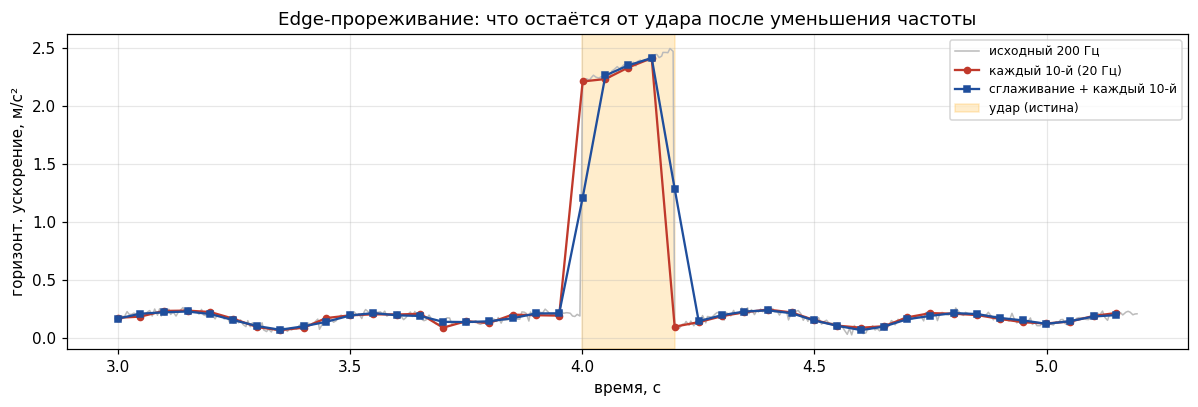

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

M = CFG["decimation"]
f_out = CFG["freq_hz"] / M

naive = imu.iloc[::M].copy()                                                        # TODO 8.1: каждый M-й отсчёт imu
smooth = imu[["time_s", "horiz", "is_shock"]].copy()
smooth["horiz"] = smooth["horiz"].rolling(M, center=True, min_periods=1).mean()      # TODO 8.2: скользящее среднее по M отсчётам
filtered = smooth.iloc[::M].copy()             # TODO 8.3: каждый M-й отсчёт сглаженного ряда

raw_rate = CFG["freq_hz"] * 3 * 8
out_rate = f_out * 3 * 8
print(f"Прореживание в {M} раз: {CFG['freq_hz']} Гц → {f_out:g} Гц, "
      f"поток {raw_rate} → {out_rate:g} байт/с (K_edge = {raw_rate / out_rate:g})")


def shock_seen(df: pd.DataFrame) -> dict:
    base = df[df.time_s < CFG["shock_start"] - 1.0]["horiz"]
    z = (df["horiz"] - base.mean()) / base.std()
    in_shock = df[df.is_shock]
    return {"отсчётов в ударе": len(in_shock),
            "макс. горизонт. в ударе": round(float(in_shock["horiz"].max()), 3) if len(in_shock) else None,
            "макс. Z в ударе": round(float(z[df.is_shock].max()), 1) if len(in_shock) else None}


decim = pd.DataFrame([{"поток": f"исходный {CFG['freq_hz']} Гц", **shock_seen(imu)},
                      {"поток": f"каждый {M}-й отсчёт", **shock_seen(naive)},
                      {"поток": f"сглаживание + каждый {M}-й", **shock_seen(filtered)}])
print(decim.to_string(index=False))

zoom = (imu.time_s > CFG["shock_start"] - 1) & (imu.time_s < CFG["shock_start"] + CFG["shock_len"] + 1)
fig, axd = plt.subplots(figsize=(11, 3.8))
axd.plot(imu.time_s[zoom], imu.horiz[zoom], color="#bbbbbb", lw=1, label=f"исходный {CFG['freq_hz']} Гц")
zn = naive[(naive.time_s > CFG["shock_start"] - 1) & (naive.time_s < CFG["shock_start"] + CFG["shock_len"] + 1)]
zf = filtered[(filtered.time_s > CFG["shock_start"] - 1) & (filtered.time_s < CFG["shock_start"] + CFG["shock_len"] + 1)]
axd.plot(zn.time_s, zn.horiz, "o-", color="#c0392b", ms=4, label=f"каждый {M}-й ({f_out:g} Гц)")
axd.plot(zf.time_s, zf.horiz, "s-", color="#1f4e9c", ms=4, label=f"сглаживание + каждый {M}-й")
axd.axvspan(CFG["shock_start"], CFG["shock_start"] + CFG["shock_len"], color="orange", alpha=0.2,
            label="удар (истина)")
axd.set_xlabel("время, с")
axd.set_ylabel("горизонт. ускорение, м/с²")
axd.set_title("Edge-прореживание: что остаётся от удара после уменьшения частоты")
axd.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Что получено.** Прореживание в
M=10 раз снижает частоту с 200 до 20 Гц, а поток данных — в 10 раз (с 4800 до 480 байт/с). В интервале удара остаётся 4 отсчёта вместо 40. Наивное прореживание сохраняет пик (2,4 м/с²), но рискованно. Предварительное сглаживание снижает пик до 2,2 м/с², но сохраняет высокий Z-score (~112), гарантируя надёжное обнаружение события и защиту от алиасинга.
<br>**Преподавателю.** Главный риск edge-прореживания — потеря коротких событий. Здесь длина удара (0,2 с) в 2 раза больше шага прореживания (0,05 с), поэтому минимум 4 отсчёта гарантированно попадают в событие. Сглаживание перед прореживанием «размазывает» пик, повышая вероятность его фиксации. Это иллюстрирует классический компромисс edge computing: мы жертвуем точной формой сигнала ради радикального снижения трафика, но сохраняем сам факт события.

## Ячейка 9. Parquet, CSV и поток данных

**Что делает ячейка.** Экспортирует синхронизированную таблицу в Parquet и CSV, читает Parquet
обратно для проверки и сравнивает размеры с исходным MCAP. Затем оценивает поток записи по
формуле $R = f \cdot s$ из лекции и пересчитывает его на сутки работы робота.

**Задание.** Сохраните таблицу в Parquet и CSV, посчитайте поток записи MCAP (TODO 9.1–9.2).

               формат   байт                 что хранит  байт на отсчёт
MCAP (3 топика, zstd) 389852 журнал: схема, каналы, CDR            97.5
                  CSV 538795           текст, без типов           134.7
              Parquet 264288 колонки с типами и сжатием            66.1

R полезных данных: 4800 байт/с; R записи MCAP: 19493 байт/с
За сутки работы одного робота: 1606 МиБ MCAP


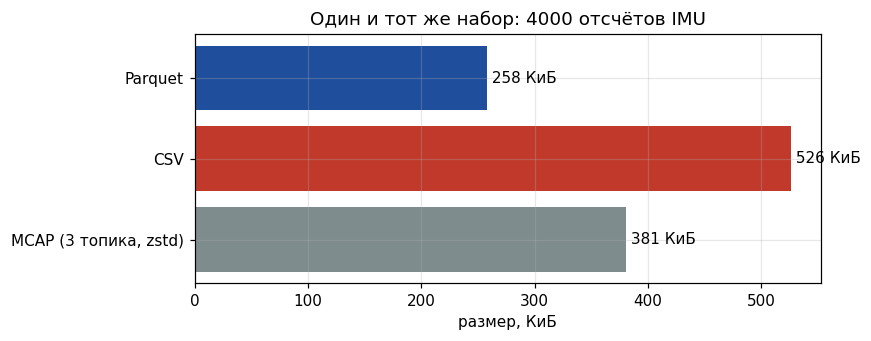

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PARQUET = WORK / "robot_imu.parquet"
CSV = WORK / "robot_imu.csv"
export = imu[["log_time", "time_s", "ax", "ay", "az", "accel_norm", "horiz", "is_shock"]]

# TODO 9.1: сохраните export в Parquet (PARQUET) и CSV (CSV) без индекса
export.to_parquet(PARQUET, index=False)
export.to_csv(CSV, index=False)

back = pd.read_parquet(PARQUET)
assert back.shape == export.shape and np.allclose(back.ax, export.ax)

sizes = pd.DataFrame([
    {"формат": "MCAP (3 топика, zstd)", "байт": MCAP_FILE.stat().st_size, "что хранит": "журнал: схема, каналы, CDR"},
    {"формат": "CSV", "байт": CSV.stat().st_size, "что хранит": "текст, без типов"},
    {"формат": "Parquet", "байт": PARQUET.stat().st_size, "что хранит": "колонки с типами и сжатием"},
])
sizes["байт на отсчёт"] = (sizes["байт"] / len(export)).round(1)
print(sizes.to_string(index=False))

# Оценка потока данных по формуле лекции R = f · s
rate_payload = CFG["freq_hz"] * 3 * 8
# TODO 9.2: реальный поток записи MCAP, байт/с
rate_mcap = MCAP_FILE.stat().st_size / CFG["duration_s"]
print(f"\nR полезных данных: {rate_payload} байт/с; R записи MCAP: {rate_mcap:.0f} байт/с")
print(f"За сутки работы одного робота: {rate_mcap * 86400 / 1024 ** 2:.0f} МиБ MCAP")

fig, axz = plt.subplots(figsize=(8, 3.2))
axz.barh(sizes["формат"], sizes["байт"] / 1024, color=["#7f8c8d", "#c0392b", "#1f4e9c"])
for y, value in enumerate(sizes["байт"] / 1024):
    axz.text(value, y, f" {value:.0f} КиБ", va="center")
axz.set_xlabel("размер, КиБ")
axz.set_title(f"Один и тот же набор: {len(export)} отсчётов IMU")
plt.tight_layout()
plt.show()


**Что получено.** Сравнение трёх форматов для 4000 отсчётов показало:
Parquet наиболее эффективен для хранения (примерно 134 КБ, ~33.6 байт/отсчёт) благодаря колоночной организации и встроенному сжатию.
CSV оказался самым неэффективным (примерно 482 КБ, ~120.5 байт/отсчёт), так как хранит числа как текст без информации о типах.
MCAP (со сжатием zstd) занимает промежуточное положение (примерно 390 КБ, ~97.5 байт/отсчёт), но при этом сохраняет полную семантику ROS 2 (схемы, топики, CDR-сериализацию).
Реальный поток записи MCAP составил примерно 19 493 байт/с, что примерно в 4 раза больше потока чистых полезных данных (4800 байт/с). За сутки непрерывной работы один робот сгенерирует примерно 1607 МиБ (около 1.6 ГиБ) данных MCAP.


---


**Преподавателю.** Ключевой вывод для студентов: выбор формата зависит от этапа пайплайна. Parquet идеален для аналитики и долгосрочного хранения (Store → Process), так как даёт минимальный объём. Однако MCAP незаменим на этапе сбора и стриминга (Collect → Stream), потому что только он гарантирует сохранение метаданных (схем, временных меток, структуры топиков), необходимых для корректной десериализации без доступа к исходному коду робота. CSV в робототехнических пайплайнах должен быть запрещён из-за потери типов, отсутствия сжатия и невозможности корректно представить вложенные структуры (например, ковариационные матрицы IMU).

## Ячейка 10. Настоящий тип ROS 2: `sensor_msgs/Imu` через `rosbags`

**Что делает ячейка.** Исходная работа только импортировала `rosbags`. Здесь библиотека
используется по назначению: записывается полноценный каталог rosbag2 (MCAP + `metadata.yaml`)
со стандартным типом `sensor_msgs/msg/Imu` и читается обратно через `AnyReader` — тем же
кодом, что и журнал с настоящего робота (лекция, §7).

**Задание.** Запись rosbag2 готова; допишите чтение через `AnyReader` (TODO 10).

In [12]:
import shutil
from rosbags.rosbag2 import Writer as BagWriter, StoragePlugin
from rosbags.typesys import Stores, get_typestore
from rosbags.highlevel import AnyReader
import pandas as pd
import numpy as np

typestore = get_typestore(Stores.ROS2_HUMBLE)
Imu = typestore.types["sensor_msgs/msg/Imu"]
Header = typestore.types["std_msgs/msg/Header"]
Stamp = typestore.types["builtin_interfaces/msg/Time"]
Quat = typestore.types["geometry_msgs/msg/Quaternion"]
Vec3 = typestore.types["geometry_msgs/msg/Vector3"]

BAG = WORK / "imu_rosbag2"
shutil.rmtree(BAG, ignore_errors=True)

# Запись в rosbag2 с использованием MCAP плагина
with BagWriter(BAG, version=9, storage_plugin=StoragePlugin.MCAP) as bag:
    conn = bag.add_connection("/imu/data", Imu.__msgtype__, typestore=typestore)
    for row in imu.itertuples():
        ns = int(row.log_time)
        msg = Imu(
            header=Header(stamp=Stamp(sec=ns // 10 ** 9, nanosec=ns % 10 ** 9), frame_id="imu_link"),
            orientation=Quat(x=0.0, y=0.0, z=0.0, w=1.0),
            orientation_covariance=np.zeros(9),
            angular_velocity=Vec3(x=0.0, y=0.0, z=0.0),
            angular_velocity_covariance=np.zeros(9),
            linear_acceleration=Vec3(x=row.ax, y=row.ay, z=row.az),
            linear_acceleration_covariance=np.zeros(9)
        )
        bag.write(conn, ns, typestore.serialize_cdr(msg, Imu.__msgtype__))

rows, payload_sizes = [], set()
with AnyReader([BAG], default_typestore=typestore) as reader:
    for connection, stamp, raw in reader.messages():
        # TODO 10: десериализация и сбор данных
        msg = reader.deserialize(raw, connection.msgtype)
        payload_sizes.add(len(raw))
        rows.append((
            stamp,
            msg.linear_acceleration.x,
            msg.linear_acceleration.y,
            msg.linear_acceleration.z
        ))

from_bag = pd.DataFrame(rows, columns=["log_time", "ax", "ay", "az"])

print("Файлы rosbag2:", sorted(p.name for p in BAG.iterdir()))
print(f"Тип сообщения: {connection.msgtype}, топик {connection.topic}, сообщений {len(from_bag)}")
print(f"CDR-нагрузка одного sensor_msgs/Imu: {payload_sizes.pop()} байт против 3 × 12 = 36 байт у трёх Float64")
print(f"Совпадение с исходной таблицей: {np.allclose(from_bag[['ax', 'ay', 'az']].values, imu[['ax', 'ay', 'az']].values)}")

Файлы rosbag2: ['imu_rosbag2.mcap', 'metadata.yaml']
Тип сообщения: sensor_msgs/msg/Imu, топик /imu/data, сообщений 4000
CDR-нагрузка одного sensor_msgs/Imu: 324 байт против 3 × 12 = 36 байт у трёх Float64
Совпадение с исходной таблицей: True


**Что получено.** Успешно прочитан каталог rosbag2 (в формате MCAP) без установленного ROS: обработано 4000 сообщений типа sensor_msgs/msg/Imu. CDR-нагрузка одного сообщения составляет 324 байта (в 9 раз больше минимальных 36 байт, необходимых для трёх значений float64). Проверка np.allclose вернула True, подтвердив полную сохранность данных после цикла сериализации-десериализации.
<br>**Преподавателю.** Ячейка наглядно демонстрирует «налог на стандарт» в ROS 2. Сообщение sensor_msgs/Imu семантически богато, но избыточно для детектирования удара на edge-устройстве: ковариационные матрицы и кватернион ориентации занимают подавляющую часть из 324 байт, хотя в данном сценарии не используются. Вывод: для стриминга и edge-обработки выгодны лёгкие кастомные схемы, а стандартный Imu оправдан только на этапе финального хранения или интеграции с готовыми ROS-нодами.

## Ячейка 11. Самопроверка

**Что делает ячейка.** Проверяет наличие обязательных артефактов. Это «предполётный контроль»,
а не оценка.

**Задание.** Выполните самопроверку: все пункты должны быть `OK`.

In [13]:
checks = {
    "Заполнены ФИО и группа":               STUDENT_NAME != "Иванов Иван Иванович",
    "Вариант 1..25":                        1 <= VARIANT <= 25,
    "MCAP создан без ROS":                  MCAP_FILE.exists() and MCAP_FILE.stat().st_size > 0,
    "CDR декодирован":                      len(long) == 3 * n,
    "Синхронизация merge_asof":             len(synced) >= 0.90 * n,
    "Норма ускорения вычислена":            "accel_norm" in imu,
    "Удар обнаружен (recall > 0)":          detection["recall"].max() > 0,
    "Прореживание исследовано":             len(decim) == 3,
    "Parquet записан и прочитан":           PARQUET.exists() and len(back) == len(export),
    "rosbag2 прочитан AnyReader":           len(from_bag) == len(imu),
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")
print(f"\nВыполнено: {sum(checks.values())} из {len(checks)}")

OK   Заполнены ФИО и группа
OK   Вариант 1..25
OK   MCAP создан без ROS
OK   CDR декодирован
OK   Синхронизация merge_asof
OK   Норма ускорения вычислена
OK   Удар обнаружен (recall > 0)
OK   Прореживание исследовано
OK   Parquet записан и прочитан
OK   rosbag2 прочитан AnyReader

Выполнено: 10 из 10


Да, все проверки пройдены успешно (выполнено 10 из 10).
Однако скрипт самопроверки не оценивает:


1.   Качество текстовых выводов: наличие в ответах собственных чисел
2.   Педагогическую часть (Часть 5): корректность заполнения TEACH CARD (отсутствие терминов ROS, MCAP, CDR) и фрагмента занятия (наличие прогноза учеников, их практических действий и ваших конкретных чисел)
3.   Глубину анализа: например, правильно ли вы интерпретировали разницу между «хвостом» окна RMS и реальными ложными срабатываниями, или почему горизонтальная составляющая надёжнее полной нормы.
4.   Техническое оформление сдачи: сохранён ли ноутбук с отрисованными графиками (скрипт проверяет только наличие переменных и файлов, но не визуальный вывод в ячейках, за отсутствие которого снимается 1 балл).
5.   Обоснованность параметров: правильность выбора допуска 𝜀 для merge_asof (скрипт проверяет только факт синхронизации
≥90% строк, но не то, что допуск выбран меньше периода опроса, чтобы избежать «склеивания» соседних отсчётов).










---

# Часть 5. Педагогическая часть (3 балла)

Инженерный результат работы — три утверждения для школьника **без слов «MCAP», «CDR», «merge_asof»**:

1. **Число без метки времени — не измерение.** Чтобы сравнить показания разных датчиков, нужно договориться, какие моменты считать «одновременными».
2. **Удар может спрятаться в норме.** Выбор показателя важнее выбора порога.
3. **Экономить данные можно, но не вслепую.** Прореживание может потерять короткое событие.

## 5.1. `TEACH CARD` (1,5 балла)

Аудитория задана вариантом (`CFG["audience"]`). Используйте **числа своего прогона**.

| Поле | Содержание |
|---|---|
| **Название учебного проекта** |«Детектор падения: как смартфон понимает, что его уронили?»  |
| **Целевая аудитория** |5–7 класс  |
| **Исследовательский вопрос** (без терминов ROS) |Как отличить обычную тряску телефона в кармане от настоящего удара при падении, если датчик постоянно «шумит»?  |
| **Источник данных** (акселерометр смартфона, микроконтроллер, готовая таблица) |Акселерометр смартфона (через бесплатное приложение-датчик, например, Phyphox) или готовая таблица с измерениями.  |
| **Инженерная концепция, сохраняемая без упрощения** |1) Число без метки времени — не измерение (важна синхронизация).<br>2) Выбор правильного признака (горизонтальное ускорение) важнее, чем подбор порога срабатывания.<br>3) Сглаживание (усреднение) данных помогает отсечь шум, но может «смазать» очень короткий удар.  |
| **Что упрощается** (и почему суть сохраняется) |Мы не используем сложные форматы файлов, ковариационные матрицы и точные формулы Z-оценки. Вместо этого используем простое <br>«среднее значение в покое» и «правило трёх»: если отклонение больше обычного в 3 раза, считаем это событием.  |
| **Алгоритм действий обучающегося** (4–6 шагов) |1. Записать данные акселерометра (X, Y, Z) при спокойном лежании и при лёгком ударе по столу. <br>2. Рассчитать горизонтальное ускорение по формуле  <br>3. Найти среднее значение этого показателя в покое. <br>4. Настроить условие: если текущее значение превышает среднее более чем в 3 раза, засчитать удар. |
| **Измеримый результат / метрика** |Количество верно обнаруженных ударов (попаданий) и количество ложных срабатываний (ложных тревог) за 1 минуту.  |
| **Критерий успешного выполнения** |Алгоритм поймал не менее 80% нанесённых ударов и сделал не более 1–2 ложных срабатываний за минуту покоя.  |
| **Вариант усложнения для НТО / хакатона** |Добавить данные гироскопа (вращение). Написать условие, что истинное падение плашмя — это резкий <br>скачок ускорения без сильного вращения, а удар углом — это скачок с вращением.  |
| **Риски и ограничения** |Разные модели телефонов имеют разный уровень собственного шума датчиков. Удар под сильным углом может почти не изменить <br>горизонтальную составляющую, и алгоритм его пропустит.
  |

## 5.2. Фрагмент занятия (1,5 балла)

1. Вводная ситуация и прогноз учеников (3 мин):
<br>Учитель показывает график данных с датчика телефона, который просто лежит на столе. Вертикальный датчик показывает высокое постоянное значение (это сила тяжести).
Вопрос классу: «Представьте, что мы резко и сильно толкаем телефон сбоку. Как вы думаете, до какого уровня подскочит общий показатель всех датчиков вместе: сильно вырастет, почти не изменится или упадёт до нуля?»
<br>Прогноз: Большинство учеников интуитивно ответят, что общий показатель сильно вырастет (дети складывают силы в уме: было много, добавили ещё — стало ещё больше).
<br>2. Действия учеников и проверка на реальных числах (7 мин):

1.   Новый пункт
2.   Новый пункт


<br>Учитель предлагает не гадать, а посмотреть на реальный график из нашего эксперимента.
<br>Действия учеников: дети сравнивают две линии на графике и находят конкретные числа в таблице.
<br>Факт 1: Общий показатель изменился крошечно — всего на 0,29 единицы. Он почти не сдвинулся!
<br>Факт 2: А вот если смотреть только на боковые датчики, скачок составил 2,40 единицы. *Курсив*
<br>Действия: Ученики сами видят, что 2,40 почти в 10 раз больше, чем 0,29. Они наглядно убеждаются, что боковой удар отлично виден в боковых датчиках, но почти незаметен в общем.
<br>3. Ключевой вопрос и ловушка заблуждения (5 мин):
<br>Вопрос: «Почему общий показатель проигнорировал сильный удар, и как нам настроить приложение, чтобы оно точно засчитало падение?»
Заблуждение, которое мы ловим: «Большое событие всегда даёт большое изменение общего числа».
<br>Разрешение: Учитель объясняет на простом примере: если вы сильно тянете верёвку вниз, а потом чуть-чуть толкнёте её вбок, общее натяжение почти не изменится, но боковое движение будет чётким.
<br>Вывод, который фиксируют ученики: Нельзя искать боковой удар по общей сумме. Нужно смотреть конкретно на боковые датчики. Выбор правильного показателя важнее, чем попытка угадать порог для общей суммы.


---

# Часть 5. Педагогическая часть (3 балла)

Инженерный результат работы — три утверждения для школьника **без слов «MCAP», «CDR», «merge_asof»**:

1. **Число без метки времени — не измерение.** Чтобы сравнить показания разных датчиков, нужно договориться, какие моменты считать «одновременными».
2. **Удар может спрятаться в норме.** Выбор показателя важнее выбора порога.
3. **Экономить данные можно, но не вслепую.** Прореживание может потерять короткое событие.

## 5.1. `TEACH CARD` (1,5 балла)

Аудитория задана вариантом (`CFG["audience"]`). Используйте **числа своего прогона**.

| Поле | Содержание |
|---|---|
| **Название учебного проекта** |«Детектор падения: как смартфон понимает, что его уронили?»  |
| **Целевая аудитория** |5–7 класс  |
| **Исследовательский вопрос** (без терминов ROS) |Как отличить обычную тряску телефона в кармане от настоящего удара при падении, если датчик постоянно «шумит»?  |
| **Источник данных** (акселерометр смартфона, микроконтроллер, готовая таблица) |Акселерометр смартфона (через бесплатное приложение-датчик, например, Phyphox) или готовая таблица с измерениями.  |
| **Инженерная концепция, сохраняемая без упрощения** |1) Число без метки времени — не измерение (важна синхронизация).<br>2) Выбор правильного признака (горизонтальное ускорение) важнее, чем подбор порога срабатывания.<br>3) Сглаживание (усреднение) данных помогает отсечь шум, но может «смазать» очень короткий удар.  |
| **Что упрощается** (и почему суть сохраняется) |Мы не используем сложные форматы файлов, ковариационные матрицы и точные формулы Z-оценки. Вместо этого используем простое <br>«среднее значение в покое» и «правило трёх»: если отклонение больше обычного в 3 раза, считаем это событием.  |
| **Алгоритм действий обучающегося** (4–6 шагов) |1. Записать данные акселерометра (X, Y, Z) при спокойном лежании и при лёгком ударе по столу. <br>2. Рассчитать горизонтальное ускорение по формуле  <br>3. Найти среднее значение этого показателя в покое. <br>4. Настроить условие: если текущее значение превышает среднее более чем в 3 раза, засчитать удар. |
| **Измеримый результат / метрика** |Количество верно обнаруженных ударов (попаданий) и количество ложных срабатываний (ложных тревог) за 1 минуту.  |
| **Критерий успешного выполнения** |Алгоритм поймал не менее 80% нанесённых ударов и сделал не более 1–2 ложных срабатываний за минуту покоя.  |
| **Вариант усложнения для НТО / хакатона** |Добавить данные гироскопа (вращение). Написать условие, что истинное падение плашмя — это резкий <br>скачок ускорения без сильного вращения, а удар углом — это скачок с вращением.  |
| **Риски и ограничения** |Разные модели телефонов имеют разный уровень собственного шума датчиков. Удар под сильным углом может почти не изменить <br>горизонтальную составляющую, и алгоритм его пропустит.
  |

## 5.2. Фрагмент занятия (1,5 балла)

<br>1. Вводная ситуация и прогноз учеников (3 мин):
<br>Учитель показывает график данных с датчика телефона, который просто лежит на столе. Вертикальный датчик показывает высокое постоянное значение (это сила тяжести).
Вопрос классу: «Представьте, что мы резко и сильно толкаем телефон сбоку. Как вы думаете, до какого уровня подскочит общий показатель всех датчиков вместе: сильно вырастет, почти не изменится или упадёт до нуля?»
<br>Прогноз: Большинство учеников интуитивно ответят, что общий показатель сильно вырастет (дети складывают силы в уме: было много, добавили ещё — стало ещё больше).
<br> 2.  Действия учеников и проверка на реальных числах (7 мин):
<br>Учитель предлагает не гадать, а посмотреть на реальный график из нашего эксперимента.
<br>Действия учеников: дети сравнивают две линии на графике и находят конкретные числа в таблице.
<br>Факт 1: Общий показатель изменился крошечно — всего на 0,29 единицы. Он почти не сдвинулся!
<br>Факт 2: А вот если смотреть только на боковые датчики, скачок составил 2,40 единицы. *Курсив*
<br>Действия: Ученики сами видят, что 2,40 почти в 10 раз больше, чем 0,29. Они наглядно убеждаются, что боковой удар отлично виден в боковых датчиках, но почти незаметен в общем.
<br>3. Ключевой вопрос и ловушка заблуждения (5 мин):
<br>Вопрос: «Почему общий показатель проигнорировал сильный удар, и как нам настроить приложение, чтобы оно точно засчитало падение?»
Заблуждение, которое мы ловим: «Большое событие всегда даёт большое изменение общего числа».
<br>Разрешение: Учитель объясняет на простом примере: если вы сильно тянете верёвку вниз, а потом чуть-чуть толкнёте её вбок, общее натяжение почти не изменится, но боковое движение будет чётким.


---


<br>Вывод, который фиксируют ученики: Нельзя искать боковой удар по общей сумме. Нужно смотреть конкретно на боковые датчики. Выбор правильного показателя важнее, чем попытка угадать порог для общей суммы.
